Import all the required libraries

In [73]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, roc_auc_score

Load and Cleaning the data

In [74]:
import os

# 1. Correct relative path from 'notebooks/' to 'data/'
data_path = os.path.join('..', 'data', 'Telco_Customer_Churn.csv')

# 2. Reload data
if os.path.exists(data_path):
    data = pd.read_csv(data_path)
    
    # 3. Clean TotalCharges (Handle empty strings and NaNs)
    data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
    data = data.dropna(subset=['TotalCharges'])
    
    # 4. Safe Mapping (Checks dtype to prevent double-mapping error)
    if data['Churn'].dtype in ['object', 'string']:
        data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})
    
    # 5. Log Transformation
    data['TotalCharges_log'] = np.log1p(data['TotalCharges'])
    
    print("✅ Success: Data reloaded, cleaned, mapped, and log-transformed.")
else:
    print(f"❌ Error: File not found at {data_path}. Please check your folder names.")

✅ Success: Data reloaded, cleaned, mapped, and log-transformed.


In [75]:
data.info()

<class 'pandas.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   str    
 1   gender            7032 non-null   str    
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   str    
 4   Dependents        7032 non-null   str    
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   str    
 7   MultipleLines     7032 non-null   str    
 8   InternetService   7032 non-null   str    
 9   OnlineSecurity    7032 non-null   str    
 10  OnlineBackup      7032 non-null   str    
 11  DeviceProtection  7032 non-null   str    
 12  TechSupport       7032 non-null   str    
 13  StreamingTV       7032 non-null   str    
 14  StreamingMovies   7032 non-null   str    
 15  Contract          7032 non-null   str    
 16  PaperlessBilling  7032 non-null   str    
 17  PaymentMeth

In [76]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'TotalCharges_log'],
      dtype='str')

Dependent and Target Features

In [77]:
target_feature = 'Churn'
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents','PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod']

Combine all features for X and y

In [78]:
# X -> independent feature
# y -> dependent feature
X = data[numeric_features + categorical_features]
y = data[target_feature]

Target -> Churn

0 -> Not churn

1 -> Churn

Observation: Imbalanced Classification Problem

In [79]:
from collections import Counter
Counter(y)

Counter({0: 5163, 1: 1869})

Split the data into train and test set

In [80]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
# stratify parameter ensures that the class imbalance is represented in both the sets [training and testing]

In [81]:
print(f"Original data churn rate: {y.mean():.4f}")
print(f"Training data churn rate: {y_train.mean():.4f}")
print(f"Testing data churn rate: {y_test.mean():.4f}")

Original data churn rate: 0.2658
Training data churn rate: 0.2657
Testing data churn rate: 0.2659


Full-Stack Pipeline

In [82]:
from sklearn.compose import ColumnTransformer

# --- 1. Numeric Preprocessing Batch
numeric_transformer = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# --- 2. Categorical Preprocessing Batch
categorical_transformer = Pipeline(steps = [
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])


# --- 3. Combine the above batches with ColumnTransformer
preprocessor = ColumnTransformer(
    transformers = [
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ],
    remainder = 'drop'
)

# --- 4. Create the final, full-stack pipeline
clf_pipeline = Pipeline(steps =[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight = 'balanced',
        random_state = 42
    ))
])

Model Training on training set

In [83]:
clf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

Model Prediction

In [84]:
y_predict = clf_pipeline.predict(X_test)
print(y_predict)

[0 1 0 ... 1 0 1]


In [85]:
y_prob = clf_pipeline.predict_proba(X_test)[:, 1]
print(y_prob)

[0.39717109 0.57209269 0.12870455 ... 0.74641361 0.03938791 0.76153802]


Model Evaluation

In [86]:
print(confusion_matrix(y_test, y_predict))

[[1110  439]
 [ 115  446]]


In [87]:
print(recall_score(y_test, y_predict))

0.7950089126559715


In [88]:
print(precision_score(y_test, y_predict))

0.503954802259887


ROC-AUC Curve

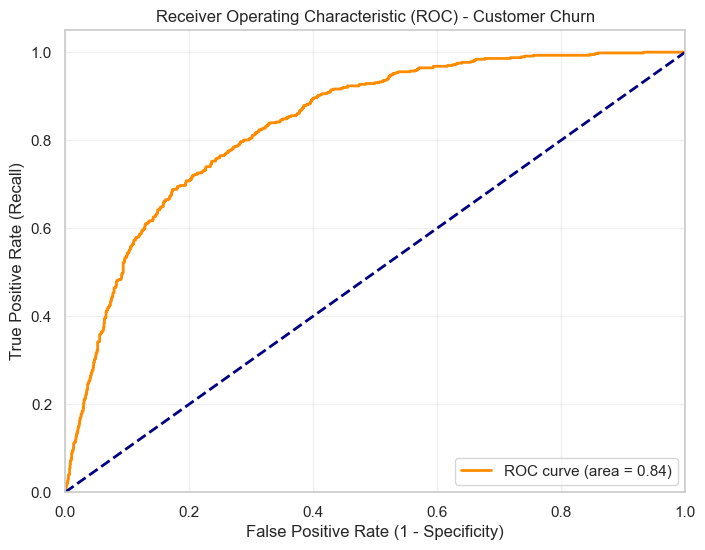

Final ROC-AUC Score: 0.8378


In [89]:
from sklearn.metrics import roc_curve, auc

# 1. Calculate the fpr, tpr and thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 2. Calculate the Area Under the Curve (AUC)
roc_auc = auc(fpr, tpr)

# 3. Plotting
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Diagonal line (random guessing)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Receiver Operating Characteristic (ROC) - Customer Churn')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"Final ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Classification Report

In [90]:
# 1. Generate the report
report = classification_report(y_test, y_predict, target_names=['Stayed (0)', 'Churned (1)'])

print("--- Machine Learning Performance: Classification Report ---")
print(report)

--- Machine Learning Performance: Classification Report ---
              precision    recall  f1-score   support

  Stayed (0)       0.91      0.72      0.80      1549
 Churned (1)       0.50      0.80      0.62       561

    accuracy                           0.74      2110
   macro avg       0.71      0.76      0.71      2110
weighted avg       0.80      0.74      0.75      2110



## Phase 1: Descriptive Statistical Profiling

### Central Tendency & Dispersion

In [91]:
# Assuming 'data' is your DataFrame from the previous steps
cols_of_interest = ['tenure', 'MonthlyCharges']

# 1. Calculate Mean (Arithmetic Average)
mean_values = data[cols_of_interest].mean()

# 2. Calculate Median (Middle Value)
median_values = data[cols_of_interest].median()

# 3. Calculate Variance (Spread of data)
variance_values = data[cols_of_interest].var()

# Combine into a summary DataFrame for easy viewing
summary_stats = pd.DataFrame({
    'Mean': mean_values,
    'Median': median_values,
    'Variance': variance_values
})

print("Central Tendency and Dispersion Statistics:")
print(summary_stats)

Central Tendency and Dispersion Statistics:
                     Mean  Median    Variance
tenure          32.421786   29.00  602.469774
MonthlyCharges  64.798208   70.35  905.165825


### Probability Distributions

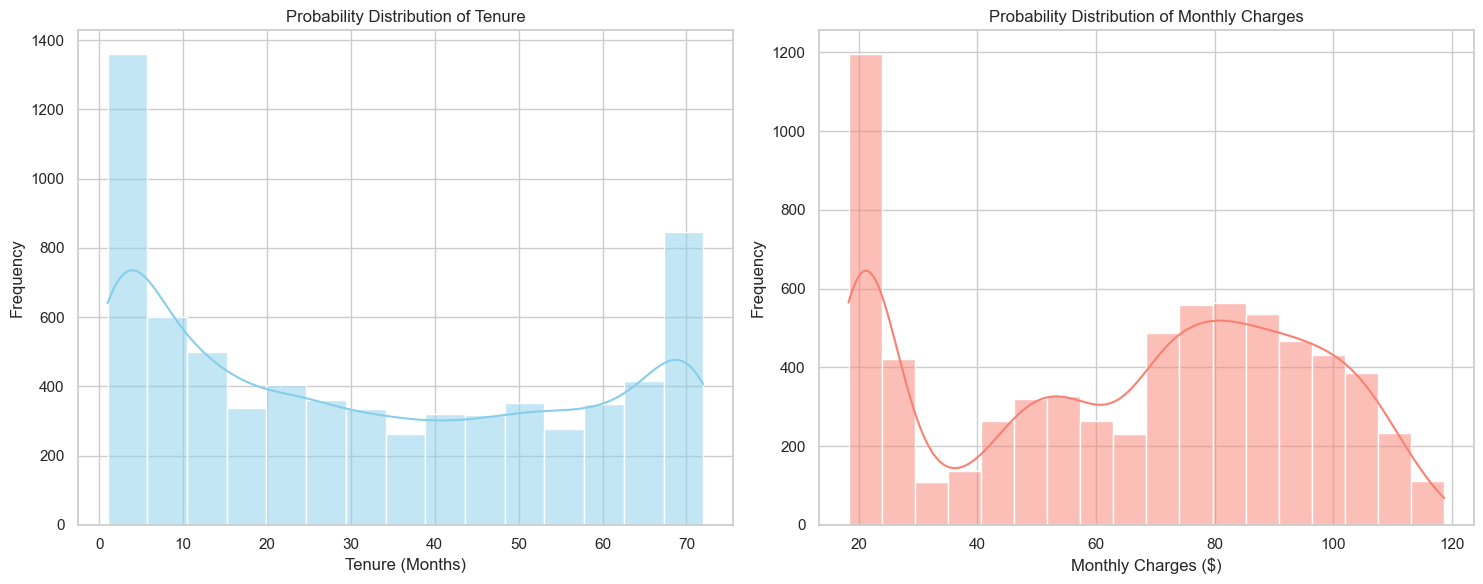

In [92]:
# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Plot Distribution for Tenure
sns.histplot(data['tenure'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Probability Distribution of Tenure')
axes[0].set_xlabel('Tenure (Months)')
axes[0].set_ylabel('Frequency')

# 2. Plot Distribution for Monthly Charges
sns.histplot(data['MonthlyCharges'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Probability Distribution of Monthly Charges')
axes[1].set_xlabel('Monthly Charges ($)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Log-Transformation for Normalization

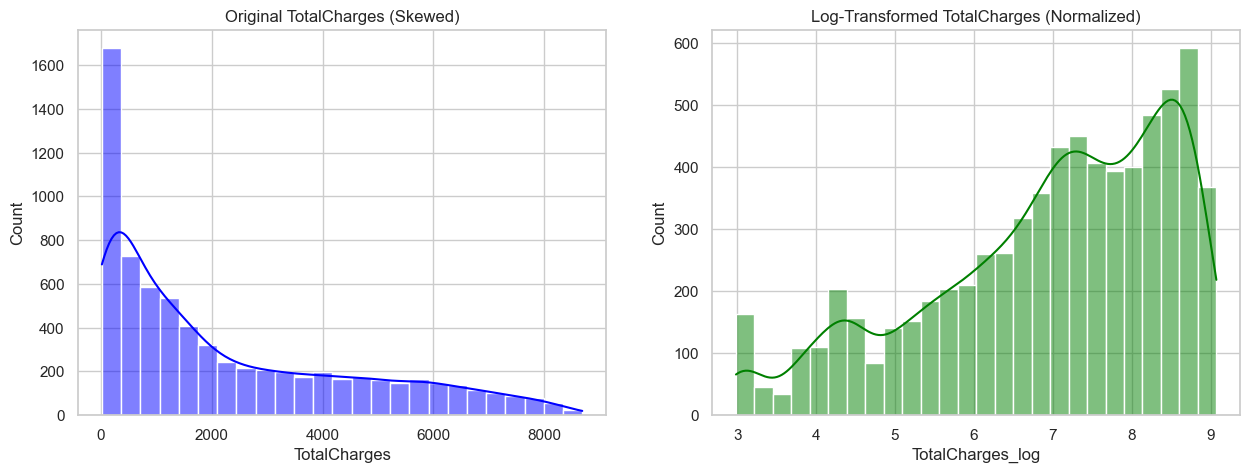

In [93]:
# Using log1p (log(1+x)) is safer as it handles potential zero values gracefully
data['TotalCharges_log'] = np.log1p(data['TotalCharges'])

# Visualization: Before vs After
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data['TotalCharges'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Original TotalCharges (Skewed)')

sns.histplot(data['TotalCharges_log'], kde=True, ax=axes[1], color='green')
axes[1].set_title('Log-Transformed TotalCharges (Normalized)')

plt.show()

### Identifying Outliers with the IQR Method

In [94]:
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    
    print(f"--- Outlier Analysis for {column} ---")
    print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f}, IQR: {IQR:.2f}")
    print(f"Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"Total Outliers detected: {len(outliers)}\n")
    return outliers

# Run detection on charge columns
monthly_outliers = detect_outliers_iqr(data, 'MonthlyCharges')
total_outliers = detect_outliers_iqr(data, 'TotalCharges')

--- Outlier Analysis for MonthlyCharges ---
Q1: 35.59, Q3: 89.86, IQR: 54.27
Bounds: [-45.82, 171.27]
Total Outliers detected: 0

--- Outlier Analysis for TotalCharges ---
Q1: 401.45, Q3: 3794.74, IQR: 3393.29
Bounds: [-4688.48, 8884.67]
Total Outliers detected: 0



## Phase 2: Inferential Hypothesis Testing

### T-test (Numerical Features)

#### Defining the Hypotheses:
##### Null Hypothesis ($H_0$): There is no significant difference in the mean TotalCharges_log between churners and non-churners ($\mu_1 = \mu_2$).
##### Alternative Hypothesis ($H_1$): There is a significant difference in the mean TotalCharges_log between the two groups ($\mu_1 \neq \mu_2$).

T-statistic: -19.6697
P-value: 4.53691184E-81


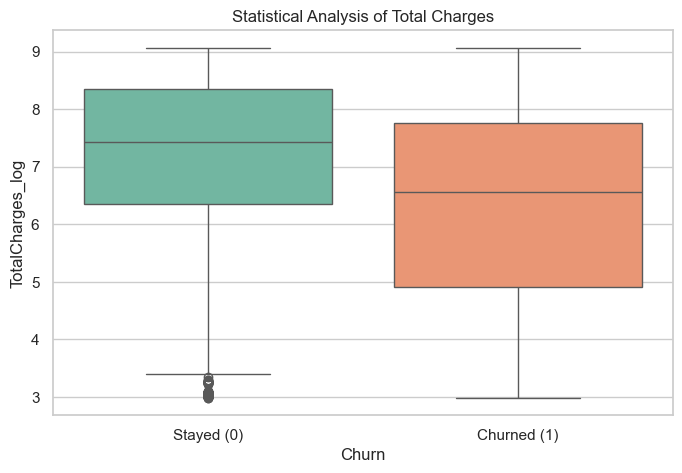

In [95]:
from scipy import stats

# Filter data to ensure no NaNs interfere with the calculation
df_stats = data.dropna(subset=['TotalCharges_log', 'Churn'])

group_churn = df_stats[df_stats['Churn'] == 1]['TotalCharges_log']
group_stayed = df_stats[df_stats['Churn'] == 0]['TotalCharges_log']

# Perform T-test with a safety check for empty groups
if len(group_churn) > 1 and len(group_stayed) > 1:
    t_stat, p_val = stats.ttest_ind(group_churn, group_stayed, equal_var=False)
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {p_val:.8E}")
else:
    print("Error: Groups are still empty. Please re-run the Data Loading cell.")

# Modernized Boxplot (fixes the 'palette' warning)
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='TotalCharges_log', data=df_stats, hue='Churn', palette='Set2', legend=False)
plt.xticks([0, 1], ['Stayed (0)', 'Churned (1)'])
plt.title('Statistical Analysis of Total Charges')
plt.show()

### Chi-Square Test (Categorical Features)

#### Defining the Hypotheses
##### Null Hypothesis ($H_0$): There is no relationship between the customer's Contract type and whether they churn (they are independent).
##### Alternative Hypothesis ($H_1$): There is a significant relationship between Contract type and churn (they are dependent).

--- Categorical Analysis: Chi-Square Test (Contract vs Churn) ---
Chi-Square Statistic: 1179.5458
P-value: 7.32618219E-257


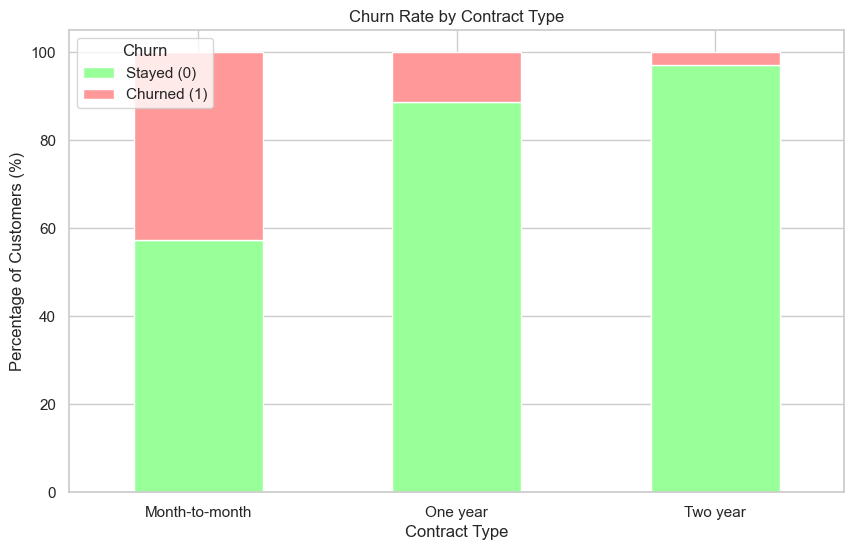

In [96]:
from scipy.stats import chi2_contingency

# 1. Create a Contingency Table (Cross-tabulation)
# This counts how many people churned vs stayed for each contract type
contingency_table = pd.crosstab(data['Contract'], data['Churn'])

# 2. Perform the Chi-Square Test
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print("--- Categorical Analysis: Chi-Square Test (Contract vs Churn) ---")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_val:.8E}") # Expected to be extremely small

# 3. Visualization: Stacked Bar Chart for Churn Rate per Contract
# Calculate percentages for better comparison
contract_churn_pct = pd.crosstab(data['Contract'], data['Churn'], normalize='index') * 100

contract_churn_pct.plot(kind='bar', stacked=True, color=['#99ff99','#ff9999'], figsize=(10, 6))
plt.title('Churn Rate by Contract Type')
plt.ylabel('Percentage of Customers (%)')
plt.xlabel('Contract Type')
plt.legend(title='Churn', labels=['Stayed (0)', 'Churned (1)'])
plt.xticks(rotation=0)
plt.show()

### Automated Chi-Square Feature Ranking

#### Establishing the Significance Level ($\alpha$)
##### In inferential statistics, the Significance Level ($\alpha$) is the probability of rejecting the null hypothesis ($H_0$) when it is actually true (a Type I error). 
##### For this dataset, we use the standard threshold of 0.05.
##### Decision Rule:If $P\text{-value} \leq 0.05$: Reject $H_0$. The association is Statistically Significant.
##### If $P\text{-value} > 0.05$: Fail to reject $H_0$. Any observed association is likely due to Random Chance.

In [97]:
import pandas as pd
from scipy.stats import chi2_contingency

# Use the categorical features list defined in your notebook
# categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', ...] 

results = []
alpha = 0.05

print(f"--- Feature Importance Ranking (Alpha = {alpha}) ---")

for col in categorical_features:
    # 1. Create contingency table
    contingency = pd.crosstab(data[col], data['Churn'])
    
    # 2. Run Chi-Square test
    chi2, p_val, dof, expected = chi2_contingency(contingency)
    
    # 3. Determine significance
    status = "Significant" if p_val <= alpha else "Not Significant"
    
    results.append({
        'Feature': col,
        'Chi-Square Stat': chi2,
        'P-Value': p_val,
        'Status': status
    })

# 4. Convert to DataFrame and rank by Chi-Square Statistic
ranking_df = pd.DataFrame(results).sort_values(by='Chi-Square Stat', ascending=False)

print(ranking_df[['Feature', 'Chi-Square Stat', 'Status']])

--- Feature Importance Ranking (Alpha = 0.05) ---
             Feature  Chi-Square Stat           Status
13          Contract      1179.545829      Significant
7     OnlineSecurity       846.677389      Significant
10       TechSupport       824.925564      Significant
6    InternetService       728.695614      Significant
15     PaymentMethod       645.429900      Significant
8       OnlineBackup       599.175185      Significant
9   DeviceProtection       555.880327      Significant
12   StreamingMovies       374.268432      Significant
11       StreamingTV       372.456502      Significant
14  PaperlessBilling       256.874908      Significant
3         Dependents       186.321639      Significant
1      SeniorCitizen       158.440816      Significant
2            Partner       157.503151      Significant
5      MultipleLines        11.271541      Significant
4       PhoneService         0.873733  Not Significant
0             gender         0.475455  Not Significant


## Phase 3: Multivariate & Relationship Analysis

### Correlation Matrix & Heatmap

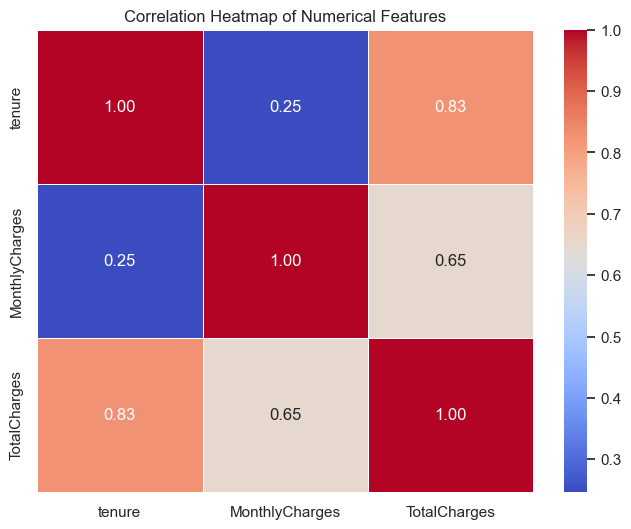

In [98]:
# 1. Select numerical features used in the model
# We include 'TotalCharges_log' if you've been using it for analysis
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
corr_matrix = data[numeric_cols].corr(method='pearson')

# 2. Visualize with a Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

### Feature Importance Analysis

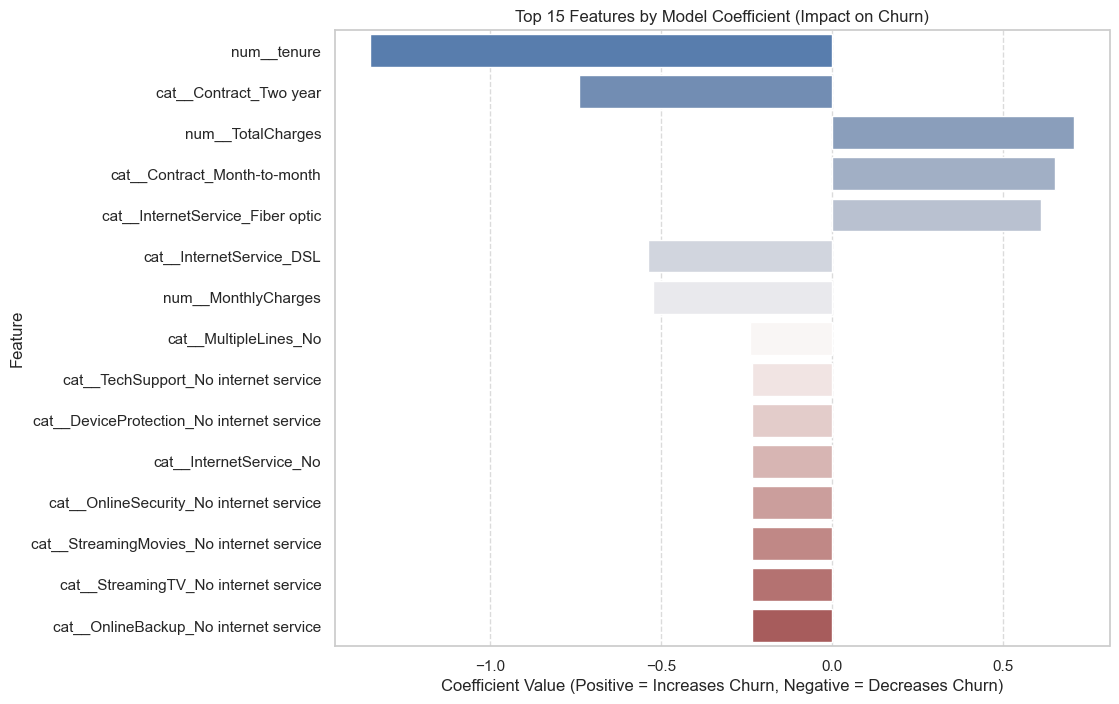

In [99]:
# 1. Extract feature names from the preprocessor
# The ColumnTransformer generates new names (especially for OneHotEncoding)
preprocessor = clf_pipeline.named_steps['preprocessor']
feature_names = preprocessor.get_feature_names_out()

# 2. Extract coefficients from the Logistic Regression model
coefficients = clf_pipeline.named_steps['classifier'].coef_[0]

# 3. Create a DataFrame for visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})

# 4. Sort and plot the top 15 most impactful features
top_features = importance_df.sort_values(by='Abs_Coefficient', ascending=False).head(15)

plt.figure(figsize=(10, 8))
sns.barplot(x='Coefficient', y='Feature', data=top_features, palette='vlag', hue='Feature', legend=False)
plt.title('Top 15 Features by Model Coefficient (Impact on Churn)')
plt.xlabel('Coefficient Value (Positive = Increases Churn, Negative = Decreases Churn)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

## Phase 4: Synthesis & Business Insight

### Threshold Analysis

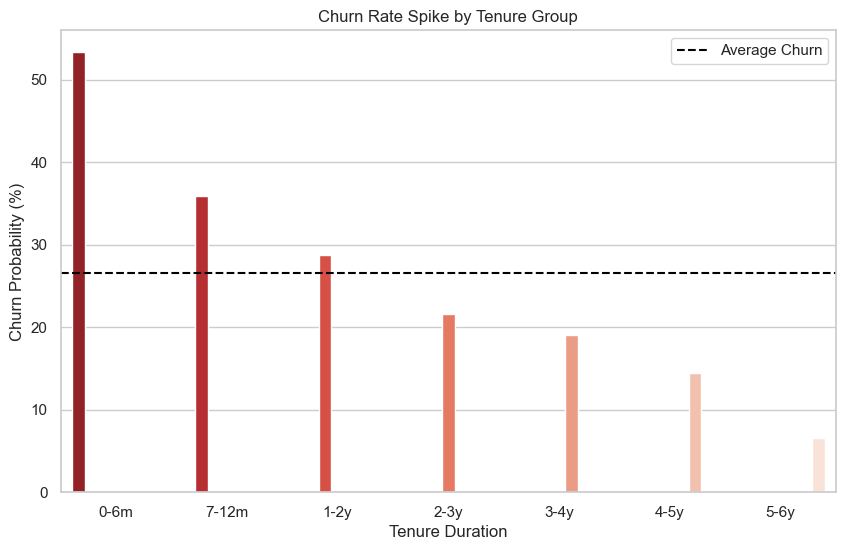

Churn Rate in first 6 months: 53.33%


In [100]:
# 1. Create tenure bins (0-6 months, 7-12, etc.)
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = ['0-6m', '7-12m', '1-2y', '2-3y', '3-4y', '4-5y', '5-6y']
data['tenure_group'] = pd.cut(data['tenure'], bins=bins, labels=labels, include_lowest=True)

# 2. Calculate Churn Rate per group
tenure_churn_rate = data.groupby('tenure_group')['Churn'].mean() * 100

# 3. Visualization
plt.figure(figsize=(10, 6))
sns.barplot(x=tenure_churn_rate.index, y=tenure_churn_rate.values, palette='Reds_r', hue=tenure_churn_rate.index, legend=False)
plt.title('Churn Rate Spike by Tenure Group')
plt.ylabel('Churn Probability (%)')
plt.xlabel('Tenure Duration')
plt.axhline(y=data['Churn'].mean()*100, color='black', linestyle='--', label='Average Churn')
plt.legend()
plt.show()

print(f"Churn Rate in first 6 months: {tenure_churn_rate['0-6m']:.2f}%")

### Segmentation: Contract Strategy

In [101]:
# 1. Group by Contract and calculate stats
contract_segmentation = data.groupby('Contract').agg({
    'Churn': ['count', 'mean', 'sum'],
    'MonthlyCharges': 'mean'
})

# Rename for clarity
contract_segmentation.columns = ['Total Customers', 'Churn Rate', 'Total Churns', 'Avg Monthly Bill']
contract_segmentation['Churn Rate'] *= 100 # Convert to %

print("--- Business Segment Analysis ---")
print(contract_segmentation.sort_values(by='Churn Rate', ascending=False))

--- Business Segment Analysis ---
                Total Customers  Churn Rate  Total Churns  Avg Monthly Bill
Contract                                                                   
Month-to-month             3875   42.709677          1655         66.398490
One year                   1472   11.277174           166         65.079416
Two year                   1685    2.848665            48         60.872374


In [102]:
import joblib
import os

# Create models directory one level up from 'notebooks/'
os.makedirs('../models', exist_ok=True)

# Save the full-stack pipeline and the feature list
joblib.dump(clf_pipeline, '../models/churn_model_v1.pkl')
joblib.dump(X.columns.tolist(), '../models/feature_columns.pkl')

print("✅ Model and Feature List saved in /models folder.")

✅ Model and Feature List saved in /models folder.
